# LASSI - Power Efficiency

***OLLAMA API*** + ***Argo Gateway API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [1]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

560.35.05


## Setup

In [1]:
import os
import json
from datetime import datetime

# Import LASSI modules
import lassi.llm_config
# import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
import lassi.pipeline_v2
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload
%reload_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
# %aimport lassi.pipeline
%aimport lassi.pipeline_v2
%aimport lassi.get_power
%aimport lassi.argostream_curl

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [2]:
def experimental_setup():
    # Load config file with source application names and input parameters
    with open("source_apps.json", "r") as f:
        source_apps = json.load(f)
    
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["30000", "100"]  ["10000", "1"]  # Usage: %s <matrix size> <repeat>
    -- jacobi [""] (none required)
    -- layout ["2500"] ["1"]
    -- atomicCost ["16", "10"] ["1"]
    -- segment-reduce ["16384", "100"] (a replacement for atomicCost, same "Data compression and reduction" category in HeCBench)
    -- dense-embedding ["100000", "128", "100"] ["10000", "8", "1"]
    -- pathfinder ["100000", "10000", "2500"] ["100000", "1000", "5"] ["10000", "1000", "1000"]  # Usage: <column length> <row length> <pyramid_height>
    -- bsearch ["8388608", "1000"] ["10000", "1"]  # Usage: <number of elements> <repeat>
    -- entropy ["8192", "8192", "500"] ["10000", "1024", "1"]  # Usage: <width> <height> <repeat>
    -- colorwheel ["10000", "256", "500000"] ["10000", "8", "1"]  # Usage: <range> <size> <repeat>
    -- randomAccess ["10"] ["1"]  # Usage: <repeat>
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]
    
    """

    # Enter source application to process through LASSI
    source_collection = "HeCBench"
    source_app = "dense-embedding"

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    """
    source_folder = source_apps[source_collection]["source_folder"]  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = source_apps[source_collection][source_app]["app_folder"]
    app_name = app_folder_name + "-cuda_main"
    build_script = False  # False (for HeCBench)

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    # THESE WILL NO LONGER BE OPTIONS
    use_context = False  # True or False -- NOT USED IN v2
    use_self_prompting = False  # True or False -- NOT USED IN v2
    use_context_summaries_only = True  # True or False
    baseline_oneshot_goal = True  # True or False -- NOT USED IN v2
    few_shot_learning = False  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False
    vary_llm_temp = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = source_apps[source_collection][source_app]["app_params"]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    # model = "gpto1mini"  # (max token = 128000)
    # model_coder = "gpto1mini"  # (max token = 128000)
    # model = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    model = "gpto3mini"  # (max token = 200000)
    model_coder = "gpto3mini"  # (max token = 200000)
    model_judge = "gpto3mini"  # (max token = 200000)

    # -- FROM OLLAMA
    # model = "qwq:latest"  # (max token = 128000)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model_judge = "qwq:latest"  # (max token = 128000)
    # model = "qwq:latest"  # (max token = 131072)
    # model = "gemma3:27b"  # crashing on code gen
    # model_coder = "gemma3:27b"
    # model = "granite3.2:8b-instruct-q8_0"
    # model_coder = "granite-code:34b-instruct-q8_0"
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
    # model_judge = "llama3.3:70b"  # (max token = 128000)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 200000
    num_ctx_coder = 200000

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpto1preview", "gpto1mini", "gpto3mini"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_" + llm_source + "_ee_hecb_selfcontext"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, app_name, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder, llm_source, use_context, use_context_summaries_only,
            few_shot_learning, context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Date-time: 04-03-2025_t07_51_39
Application: dense-embedding

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpto3mini
Model coder: gpto3mini
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

Power measurement: True


***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v2) *****


----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
cl

Waiting for the system to settle down for 1 seconds...: 100%|█████████████████████████████| 1/1 [00:01<00:00,  1.00s/it]


Working directory: source_codes/HeCBench/dense-embedding
Execute command: ['./dense-embedding-cuda_main', '100000', '128', '100']

Number of rows in the embedding table: 100000
Batch size: 128

Embedding dimension: 768
block size: 128
Average execution time of dense embedding kernel (k1): 397.094116 (us)
Average execution time of dense embedding kernel (k2): 373.324219 (us)
PASS
block size: 256
Average execution time of dense embedding kernel (k1): 219.374847 (us)
Average execution time of dense embedding kernel (k2): 209.613007 (us)
PASS
block size: 512
Average execution time of dense embedding kernel (k1): 156.646057 (us)
Average execution time of dense embedding kernel (k2): 151.133942 (us)
PASS
block size: 1024
Average execution time of dense embedding kernel (k1): 93.082077 (us)
Average execution time of dense embedding kernel (k2): 89.392113 (us)
PASS

Embedding dimension: 2048
block size: 128
Average execution time of dense embedding kernel (k1): 1043.761475 (us)
Average executi

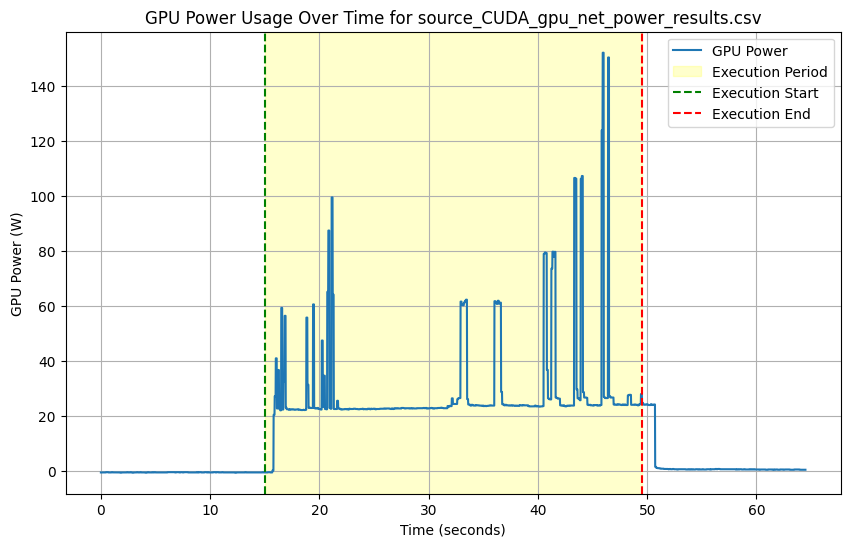

Start time: 15.001 -- End time: 49.484
Total GPU energy consumption for source_CUDA_gpu_net_power_results.csv:
  0.000276 kWh
  0.2761 Wh
  993.91 J
Average GPU power: 28.83 W
 with sample standard deviation: 18.95
Total Energy During Exe Runtime:   993.91 J
Code execution duration: 34.48 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.76 W, P0



Measure system idle power...
Duration for idle time measurement: 34.48
GPU power data has been written to idle__gpu_net_power_results.csv


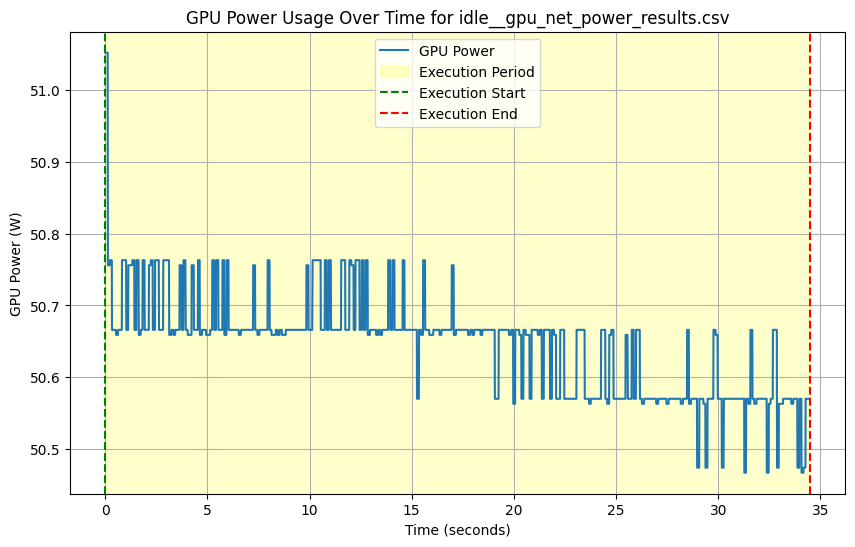

Start time: 0 -- End time: 34.484
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000485 kWh
  0.4851 Wh
  1746.27 J
Average GPU power: 50.65 W
 with sample standard deviation: 0.07
Total Energy During Exe Runtime:   1746.27 J
Code execution duration: 34.48 seconds
----------------------------------------------------------------------------------------------------------------------------------------


----- STARTING FIRST STAGE: ZERO-SHOT BASE LLM REFACTORING -----


----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.56 W, P0


----- REVIEW THE ZERO-SHOT INSTRUCTIONS TASK PROMPT  (prompt without code, token count: 24): 


--> ... initial zero-shot attempt: prompt the LLM to generate code.



----- STARTING CODE GENERATION -----


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA eng



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39

Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.38 W, P0


Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39', '100000', '128', '100']

Number of rows in the embedding table: 100000
Batch size: 128

Embedding dimension: 768
block size: 128
Average execution time of dense embedding kernel (k1): 372.746246 (us)
Average execution time of dense embedding kernel (k2): 372.131836 (us)
PASS
block size: 256
Average execution time of dense embedding kernel (k1): 209.930252 (us)
Average execution time of dense embedding kernel (k2): 209.745911 (us)
PASS
block size: 512
Average execution time of dense embedding kernel (k1): 151.070724 (us)
Average execution time of dense embedding kernel (k2): 151.080963 (us)
PASS
block size: 1024
Average execution time of dense embedding kernel (k1): 89.210876 (us)
Average execution time of dense embedding kernel (k2): 89.343994 (us)
PASS

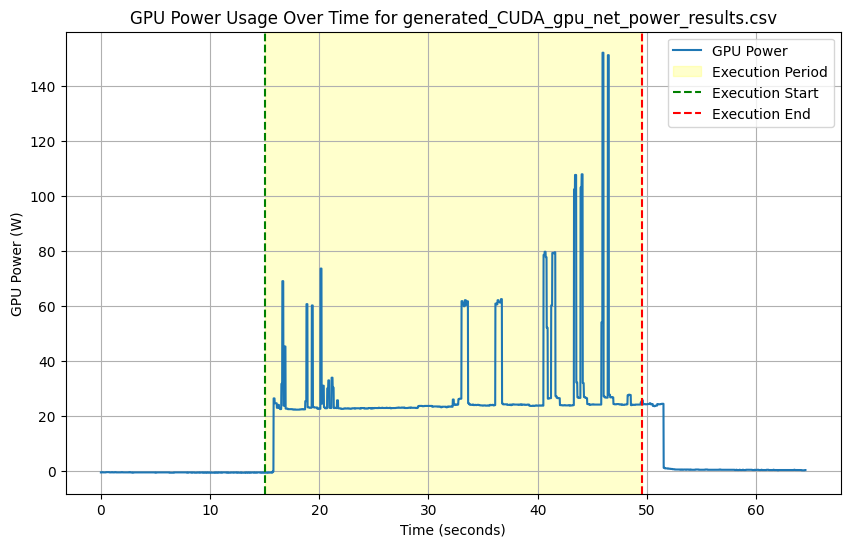

Start time: 15.001 -- End time: 49.521
Total GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000271 kWh
  0.2715 Wh
  977.23 J
Average GPU power: 28.31 W
 with sample standard deviation: 17.40
Total Energy During Exe Runtime:   977.23 J
Code execution duration: 34.52 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 51.24 W, P0



--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functiona



----- LLM RESPONSE: code validation judge -----



Below is our evaluation:

1. Both versions compute the same operation over the input, dense, and offset arrays. The reference function is unchanged and both CUDA kernels (dense_esuhm and dense_esuhm2) follow the same inner-loop logic—each thread picks an index in the embedding dimension and then iterates (by steps of the embedding dimension) over the “range” computed from the offset array to perform output = input + dense_elem.

2. The refactored code introduces standard energy-efficiency improvements:
  • It adds __restrict__ qualifiers for pointer parameters (input, dense, output, and offset) so that the compiler can perform more aggressive optimizations.
  • It caches offset values (start and range) in registers, rather than calculating them repeatedly.
  • Instead of using busy-waiting with the C++ chrono API, it now uses cudaEvent-based timing, reducing CPU overhead.
  • It employs a grid-stride loop for processing over embedding dimensions, which saves redundant kernel launches/idle threads.
  • It includes an error-checking macro (CUDA_CHECK) for robust error handling.

3. In terms of output, the refactored application prints the same texts (number of rows, batch size, embedding dimension, block sizes, average execution times for both kernels, and PASS/FAIL) and the printed timing numbers are within the same ballpark as the original. Minor differences in the numerical values (execution times) are acceptable since they result from the changes meant to improve efficiency.

4. The overall computations and memory transfers (including the reference validation loop) are kept identical. The standard output layout and content are preserved.

Based on the above careful review, the REFACTORED CODE is functionally equivalent to the SOURCE CODE and produces (nearly) identical output while incorporating energy-efficiency improvements.

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 993.91
  Refactored code: 977.23
----- Average power (W) -----
  Source code: 28.83
  Refactored code: 28.31
----- Runtime (s) -----
  Source code: 34.48
  Refactored code: 34.52
----- Tracking metrics -----
  Energy (J) history:  [993.91, 977.23]
  Ave Power (W) history:  [28.83, 28.31]
  Runtime (s) history:  [34.48, 34.52]
  Valid code history:  ['SOURCE', 'basellm_VALID']


***** Generated refactored code is more energy efficient than source or previous code! *****
... following refactor index: 0




CHANGE PROMPT STRATEGY! -----


----- STARTING LASSI: ITERATIVE SELF-PROMPTING WITH CONTEXT AND SELF-CORRECTION -----


--> ... prompt LLM to summarize context knowledge.


=====< LLM Prompt Not Shown >=====





----- CONTEXT KNOWLEDGE SUMMARY -----
 (generated by the LLM)



Below is a summary of the key points from the background knowledge that are relevant to refactoring code for energy efficiency:

1. Kernel and Thread Organization:
   - Use __global__ kernels with a well-arranged thread hierarchy (blocks and grids) to maximize parallelism. Setting thread blocks to sizes that are multiples of 32 (a full warp) minimizes idle cycles and divergence.
   - When possible, simplify control flow across threads so that whole warps execute the same instructions, thereby reducing diverging execution paths.

2. Memory Hierarchy and Transfers:
   - Minimize global memory accesses since they incur high latency. Use shared memory for frequently accessed data to reduce energy-intensive memory traffic.
   - Avoid unnecessary transfers between host and device memory. Batch small memory transfers into larger, contiguous ones and consider using page-locked (pinned) memory for higher transfer bandwidth.
   - Create and operate on intermediate data structures directly in device memory, eliminating extra host-device mapping and copy overhead.

3. Asynchronous Operations and Latency Hiding:
   - Use asynchronous memory copy and kernel execution features (e.g., cudaMemcpyAsync, asynchronous barriers, and pipelines) to overlap data transfer with computation, thereby reducing idle cycles and overall energy consumption.
   - Synchronize threads using lightweight primitives like __syncthreads() and cluster-specific synchronization where available to avoid idling processing elements.

4. Math and Computation Efficiency:
   - Choose fast math functions (e.g., __sinf, __expf, sincosf) over their more precise counterparts when lower accuracy is acceptable. Also, use specialized functions (e.g., sinpi instead of sin) to reduce expensive operations like argument reduction.
   - For small integer exponents, prefer explicit multiplication rather than using generic pow() functions. This can reduce register pressure and the overall energy required for computation.

5. Optimize Loop Counters and Arithmetic:
   - Use signed integers for loop counters to enable more aggressive compiler optimization through strength reduction and other optimizations.
   - Replace expensive division and modulo operations with bitwise shifts and bitmasking when the divisor is a power of two.

6. Occupancy and Resource Utilization:
   - Maintain sufficient active threads per multiprocessor to hide memory latency and improve overall energy efficiency. Good occupancy also means that the scheduler can better hide waiting periods while memory accesses complete.
   - Optimize usage of registers and shared memory, as reduced pressure on these limited resources can lead to fewer excess cycles and better energy profiles.

By applying these key concepts during refactoring, one can reduce the number of power-hungry operations (like global memory access and warp divergence), streamline kernel execution, and better utilize available hardware resources—all of which contribute to improved energy efficiency across both CPU and GPU.

... (9 outputs left out)



----- THE REFACTORING PLAN PROMPT  (prompt with code, token count: 3330): 



----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency improvement with code, token count: 3448): 

--> ... prompt LLM to generate code for energy efficiency -- new refactoring plan.



----- STARTING CODE GENERATION -----


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all original functionality and expected output of the provided code. You must also carefully read and incorporate the best practices and CUDA optimization techniques from the provided background documents and refactoring plans. You always surround your generated code with the three characters ```.

PROMPT: Carefully follow these instructions step-by-step:
STEP 1: Select the most impactful of the improvements outlined in your refactoring plan t



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39

Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 50.76 W, P0


Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39', '100000', '128', '100']

Number of rows in the embedding table: 100000
Batch size: 128

Embedding dimension: 768
block size: 128
Average execution time of dense embedding kernel (k1): 373.145599 (us)
Average execution time of dense embedding kernel (k2): 371.640320 (us)
PASS
block size: 256
Average execution time of dense embedding kernel (k1): 209.367050 (us)
Average execution time of dense embedding kernel (k2): 208.957443 (us)
PASS
block size: 512
Average execution time of dense embedding kernel (k1): 150.865921 (us)
Average execution time of dense embedding kernel (k2): 150.968323 (us)
PASS
block size: 1024
Average execution time of dense embedding kernel (k1): 89.497604 (us)
Average execution time of dense embedding kernel (k2): 89.395195 (us)
PASS

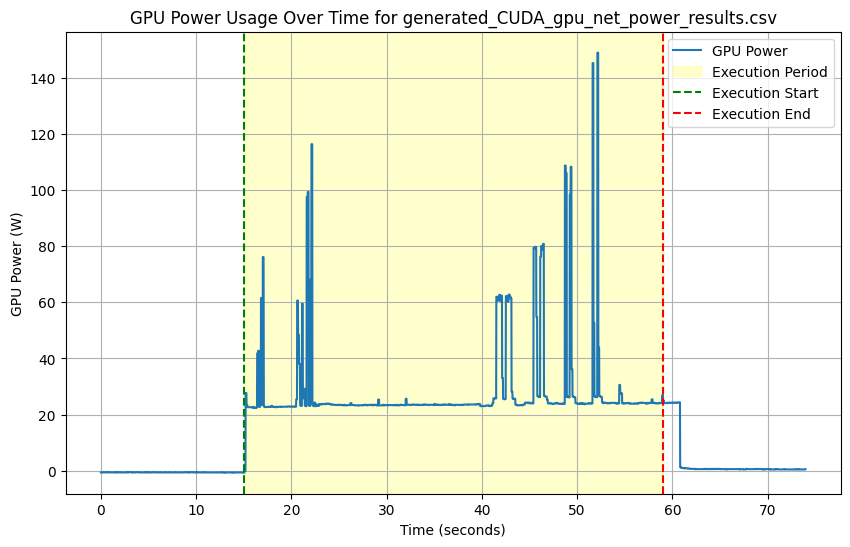

Start time: 15.001 -- End time: 58.968
Total GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000346 kWh
  0.3463 Wh
  1246.65 J
Average GPU power: 28.36 W
 with sample standard deviation: 16.45
Total Energy During Exe Runtime:   1246.65 J
Code execution duration: 43.97 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 51.73 W, P0



--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving a



----- LLM RESPONSE: code validation judge -----



Both implementations perform the same high‐level tasks:
 • They prepare input, dense, output, and offset arrays
 • They compute a reference output using the same nested-loop algorithm
 • They launch two CUDA kernels (dense_esuhm and dense_esuhm2) that add a selected dense element to the input data, with the same looping over embedding dimensions and nested indices
 • They compare the kernel outputs against the reference

The refactored code makes several optimizations:
 – It qualifies pointer parameters with __restrict__ to aid compiler optimizations.
 – It caches offset values (start, range) in registers.
 – It uses a grid-stride loop pattern to reduce thread idling.
 – It uses CUDA events for timing (removing CPU busy‐waiting) rather than std::chrono.
 – It replaces standard memory allocation with pinned host memory via cudaHostAlloc, which can lead to improved transfer efficiency.

Despite these changes, the overall structure remains as before: both kernels loop over the embedding dimension and adjust indices in similar fashion. The printed output messages (block size, average execution time of k1/k2, PASS/FAIL) are formatted and ordered identically. The measured execution times differ only slightly (consistent with the improvements in efficiency), and the PASS/FAIL checks validate that numerical results match within the same tolerance.

Thus, the refactored code preserves all intended functionality and nearly identical standard output while introducing optimizations for energy and runtime efficiency.

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 993.91
  Refactored code: 1246.65
----- Average power (W) -----
  Source code: 28.83
  Refactored code: 28.36
----- Runtime (s) -----
  Source code: 34.48
  Refactored code: 43.97
----- Tracking metrics -----
  Energy (J) history:  [993.91, 977.23, 1246.65]
  Ave Power (W) history:  [28.83, 28.31, 28.36]
  Runtime (s) history:  [34.48, 34.52, 43.97]
  Valid code history:  ['SOURCE', 'basellm_VALID', 'VALID']


***** Generated refactored code is NOT more energy efficient than source or previous code... *****

 ----- ENERGY EFFICIENCY REVIEW: Let's provide feedback on the energy consumption. -----




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 1 -----
... Prior code index selected to refactor: 2


----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, token count: 3549): 

--> ... prompt LLM to generate code for energy efficiency -- improve



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39

Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 51.24 W, P0


Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39', '100000', '128', '100']

Number of rows in the embedding table: 100000
Batch size: 128

Embedding dimension: 768
block size: 128
Average execution time of dense embedding kernel (k1): 372.367340 (us)
Average execution time of dense embedding kernel (k2): 371.937317 (us)
PASS
block size: 256
Average execution time of dense embedding kernel (k1): 209.213455 (us)
Average execution time of dense embedding kernel (k2): 209.326080 (us)
PASS
block size: 512
Average execution time of dense embedding kernel (k1): 150.732803 (us)
Average execution time of dense embedding kernel (k2): 150.743042 (us)
PASS
block size: 1024
Average execution time of dense embedding kernel (k1): 89.405441 (us)
Average execution time of dense embedding kernel (k2): 89.200645 (us)
PASS

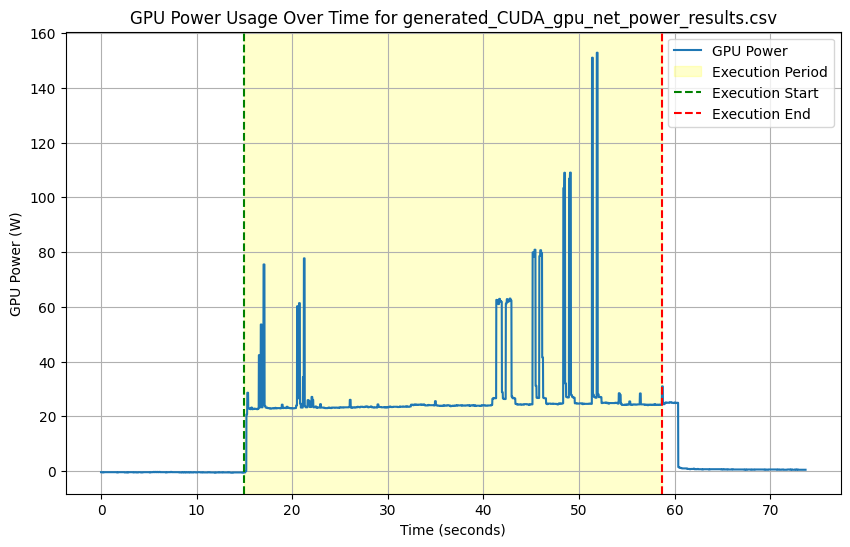

Start time: 15.001 -- End time: 58.684
Total GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000338 kWh
  0.3377 Wh
  1215.86 J
Average GPU power: 27.84 W
 with sample standard deviation: 15.27
Total Energy During Exe Runtime:   1215.86 J
Code execution duration: 43.68 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 52.22 W, P0



--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving a



----- LLM RESPONSE: code validation judge -----



The REFACTORED CODE still implements the same reference function and the same two CUDA kernels (dense_esuhm and dense_esuhm2) with only minor changes: additional __restrict__ qualifiers, caching of the starting offset, and a grid‐stride loop approach—which are implemented to improve efficiency without altering the arithmetic and loop structure used to update the output. The host code still allocates memory (although now using pinned (page‐locked) memory), sets up the same input data (using the same random seed), and uses essentially the same loop over embedding dimensions and block sizes. The printed output (the introductory configuration lines, average execution times per kernel variant for several block sizes, and “PASS” on successful comparison) follows the same layout and content with only minor numerical differences that are acceptable given the refactoring’s focus on efficiency improvements. 

Thus, the refactored code preserves all intended functionality and produces equivalent standard output as the source code.

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 993.91
  Refactored code: 1215.86
----- Average power (W) -----
  Source code: 28.83
  Refactored code: 27.84
----- Runtime (s) -----
  Source code: 34.48
  Refactored code: 43.68
----- Tracking metrics -----
  Energy (J) history:  [993.91, 977.23, 1246.65, 1215.86]
  Ave Power (W) history:  [28.83, 28.31, 28.36, 27.84]
  Runtime (s) history:  [34.48, 34.52, 43.97, 43.68]
  Valid code history:  ['SOURCE', 'basellm_VALID', 'VALID', 'VALID']


***** Generated refactored code is NOT more energy efficient than source or previous code... *****

 ----- ENERGY EFFICIENCY REVIEW: Let's provide feedback on the energy consumption. -----




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 2 -----
... Prior code index selected to refactor: 3


----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, token count: 3624): 

--> ... prompt LLM to generate code 



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39

Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 51.64 W, P0


Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39', '100000', '128', '100']

Number of rows in the embedding table: 100000
Batch size: 128

Embedding dimension: 768
block size: 128
Average execution time of dense embedding kernel (k1): 372.428833 (us)
Average execution time of dense embedding kernel (k2): 371.609619 (us)
PASS
block size: 256
Average execution time of dense embedding kernel (k1): 209.561600 (us)
Average execution time of dense embedding kernel (k2): 209.438736 (us)
PASS
block size: 512
Average execution time of dense embedding kernel (k1): 150.865921 (us)
Average execution time of dense embedding kernel (k2): 150.804489 (us)
PASS
block size: 1024
Average execution time of dense embedding kernel (k1): 89.364479 (us)
Average execution time of dense embedding kernel (k2): 89.333763 (us)
PASS

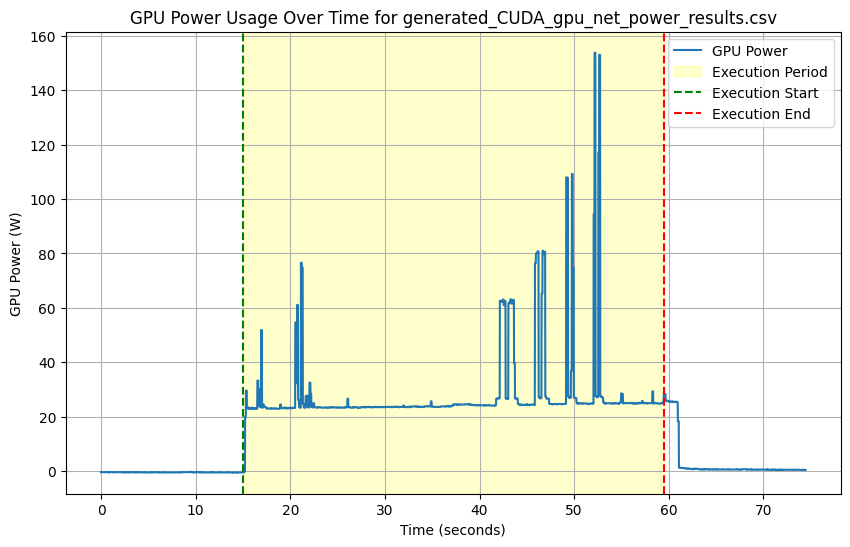

Start time: 15.001 -- End time: 59.458
Total GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000350 kWh
  0.3501 Wh
  1260.48 J
Average GPU power: 28.36 W
 with sample standard deviation: 16.04
Total Energy During Exe Runtime:   1260.48 J
Code execution duration: 44.46 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 52.33 W, P0



--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving a



----- LLM RESPONSE: code validation judge -----



The two versions perform exactly the same computation. In the original code there are two separate kernels (dense_esuhm and dense_esuhm2) that both loop over the embedding dimension and add corresponding dense values to sections of the input. In the refactored code these two kernels have been unified by extracting the common computation into a helper device function (dense_kernel_impl), and then both kernels simply call this implementation. The refactored code still uses the same method for computing the offsets, iterating over the embedding dimensions, and performing the per‐element addition. In addition, the refactored version preserves the same printed header information and prints the “PASS” message after comparing the device output with the CPU reference.

Other changes—such as the use of pinned host memory, asynchronous streams, CUDA events for timing, and an error-check macro—are improvements aimed at increasing energy efficiency and reliability without altering the core logic or the expected output layout. The small numerical differences in the reported execution times are reasonable given that the refactored code uses different timing mechanisms and memory allocation strategies that are consistent with its improvements.

Therefore, the refactored code maintains the intended functionality and produces equivalent standard output.

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 993.91
  Refactored code: 1260.48
----- Average power (W) -----
  Source code: 28.83
  Refactored code: 28.36
----- Runtime (s) -----
  Source code: 34.48
  Refactored code: 44.46
----- Tracking metrics -----
  Energy (J) history:  [993.91, 977.23, 1246.65, 1215.86, 1260.48]
  Ave Power (W) history:  [28.83, 28.31, 28.36, 27.84, 28.36]
  Runtime (s) history:  [34.48, 34.52, 43.97, 43.68, 44.46]
  Valid code history:  ['SOURCE', 'basellm_VALID', 'VALID', 'VALID', 'VALID']


***** Generated refactored code is NOT more energy efficient than source or previous code... *****

 ----- ENERGY EFFICIENCY REVIEW: Let's provide feedback on the energy consumption. -----




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 3 -----
... Prior code index selected to refactor: 4


----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, token count: 3551): 

--> 



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39

Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 51.64 W, P0


Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39', '100000', '128', '100']

Number of rows in the embedding table: 100000
Batch size: 128

Embedding dimension: 768
block size: 128
Average execution time of dense embedding kernel (k1): 316.805115 (us)
Average execution time of dense embedding kernel (k2): 317.583374 (us)
PASS
block size: 256
Average execution time of dense embedding kernel (k1): 182.056946 (us)
Average execution time of dense embedding kernel (k2): 181.780472 (us)
PASS
block size: 512
Average execution time of dense embedding kernel (k1): 108.390404 (us)
Average execution time of dense embedding kernel (k2): 108.185593 (us)
PASS
block size: 1024
Average execution time of dense embedding kernel (k1): 73.492477 (us)
Average execution time of dense embedding kernel (k2): 73.379837 (us)
PASS

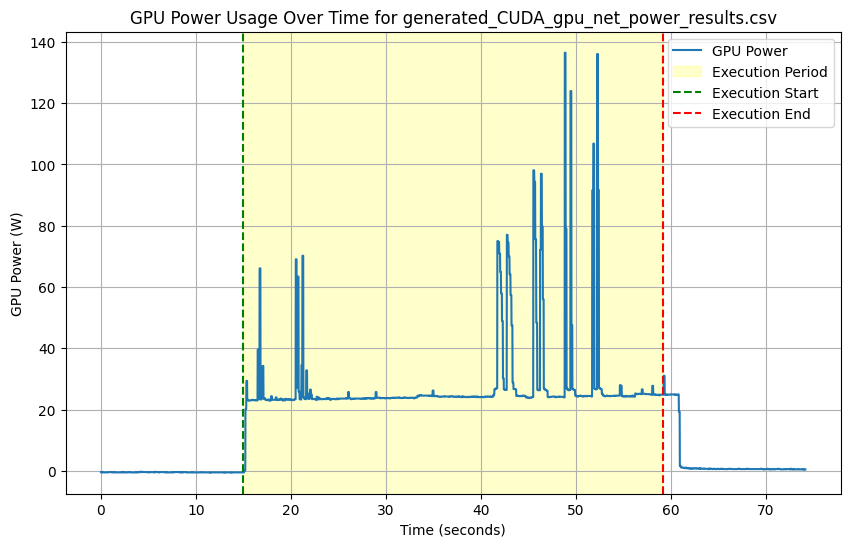

Start time: 15.001 -- End time: 59.166
Total GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000345 kWh
  0.3453 Wh
  1242.90 J
Average GPU power: 28.15 W
 with sample standard deviation: 15.29
Total Energy During Exe Runtime:   1242.90 J
Code execution duration: 44.17 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 52.42 W, P0



--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving a



----- LLM RESPONSE: code validation judge -----



The REFACTORED CODE implements the same computation for the output. It preserves the kernel’s original loop logic (adding the corresponding dense element to each input element for each batch and index) by calling an internal helper (dense_kernel_impl) in both kernels and by keeping the same computation “output = input + dense_elem.” Although it “fuses” the repeat loop into the kernel (with the dev_repeat constant) rather than launching many kernel calls from the host, every iteration reassigns the same computed result (as in the original code), so the final output exactly matches the reference output produced by the SOURCE CODE.

On the host side the printed text (“Number of rows …”, “Batch size: …”, “Embedding dimension: …”, “block size: …”, “Average execution time of dense embedding kernel (k1/k2): … (us)” and finally “PASS” when correct) is kept intact. The only differences in numerical timing values or energy metrics (e.g. a longer kernel duration or higher total energy) are minor and can be the result of the refactoring choices (using pinned memory, internal looping, CUDA events versus chrono, etc.) while still matching the intended functionality and output layout.

Thus, all intended functionality and standard output (in both layout and content) are preserved. 

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 993.91
  Refactored code: 1242.9
----- Average power (W) -----
  Source code: 28.83
  Refactored code: 28.15
----- Runtime (s) -----
  Source code: 34.48
  Refactored code: 44.17
----- Tracking metrics -----
  Energy (J) history:  [993.91, 977.23, 1246.65, 1215.86, 1260.48, 1242.9]
  Ave Power (W) history:  [28.83, 28.31, 28.36, 27.84, 28.36, 28.15]
  Runtime (s) history:  [34.48, 34.52, 43.97, 43.68, 44.46, 44.17]
  Valid code history:  ['SOURCE', 'basellm_VALID', 'VALID', 'VALID', 'VALID', 'VALID']


***** Generated refactored code is NOT more energy efficient than source or previous code... *****

 ----- ENERGY EFFICIENCY REVIEW: Let's provide feedback on the energy consumption. -----




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 4 -----
... Prior code index selected to refactor: 5


----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with co



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39

Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 51.74 W, P0


Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39', '100000', '128', '100']

Number of rows in the embedding table: 100000
Batch size: 128

Embedding dimension: 768
block size: 128
Average execution time of dense embedding kernel (k1): 316.917755 (us)
Average execution time of dense embedding kernel (k2): 317.061127 (us)
PASS
block size: 256
Average execution time of dense embedding kernel (k1): 181.780472 (us)
Average execution time of dense embedding kernel (k2): 181.852173 (us)
PASS
block size: 512
Average execution time of dense embedding kernel (k1): 107.929596 (us)
Average execution time of dense embedding kernel (k2): 108.287994 (us)
PASS
block size: 1024
Average execution time of dense embedding kernel (k1): 73.420799 (us)
Average execution time of dense embedding kernel (k2): 73.431038 (us)
PASS

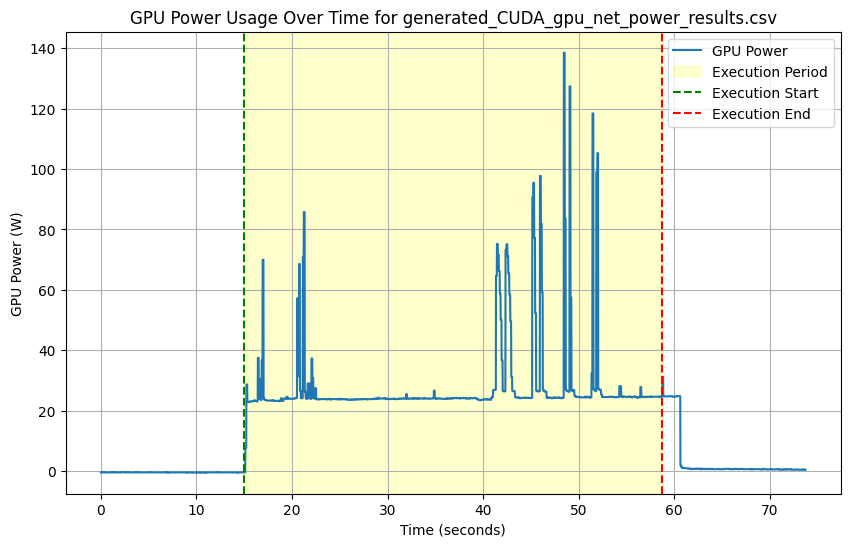

Start time: 15.001 -- End time: 58.74
Total GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000343 kWh
  0.3427 Wh
  1233.78 J
Average GPU power: 28.21 W
 with sample standard deviation: 15.10
Total Energy During Exe Runtime:   1233.78 J
Code execution duration: 43.74 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 52.52 W, P0



--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving al



----- LLM RESPONSE: code validation judge -----



The refactored code preserves the intended functionality and produces standard output that has the same layout and content (with only minor timing differences that are acceptable because of the energy‐efficient improvements). In the refactored version the two kernel variants (k1 and k2) are merged into one unified implementation (with an inner repeat loop performed on the device via a device constant) so that both “versions” compute the same result as in the source code. The CPU reference computation remains unchanged and the verification loop compares the refactored output to the reference result exactly as before. The kernel’s inner loop over repeat iterations (done on‐device in the refactored version) reproduces the effect of launching the kernel repeatedly in the source code. Also, the printed messages (including block size lines, average execution time messages and “PASS” messages) exactly follow the original layout and content. 

Thus, after careful evaluation, the REFACTORED CODE is functionally equivalent.

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 993.91
  Refactored code: 1233.78
----- Average power (W) -----
  Source code: 28.83
  Refactored code: 28.21
----- Runtime (s) -----
  Source code: 34.48
  Refactored code: 43.74
----- Tracking metrics -----
  Energy (J) history:  [993.91, 977.23, 1246.65, 1215.86, 1260.48, 1242.9, 1233.78]
  Ave Power (W) history:  [28.83, 28.31, 28.36, 27.84, 28.36, 28.15, 28.21]
  Runtime (s) history:  [34.48, 34.52, 43.97, 43.68, 44.46, 44.17, 43.74]
  Valid code history:  ['SOURCE', 'basellm_VALID', 'VALID', 'VALID', 'VALID', 'VALID', 'VALID']


***** Generated refactored code is NOT more energy efficient than source or previous code... *****

 ----- ENERGY EFFICIENCY REVIEW: Let's provide feedback on the energy consumption. -----




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 5 -----
... Prior code index selected to refactor: 6


----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (ener



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39']

***** Compilation failed.
 Error message: 
/usr/bin/ld: /usr/lib/gcc/x86_64-linux-gnu/13/../../../x86_64-linux-gnu/Scrt1.o: in function `_start':
(.text+0x1b): undefined reference to `main'
collect2: error: ld returned 1 exit status


Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39


----- SELF-CORRECT



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39

Before exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 51.55 W, P0


Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39', '100000', '128', '100']

GPU power data has been written to generated_CUDA_gpu_net_power_results.csv


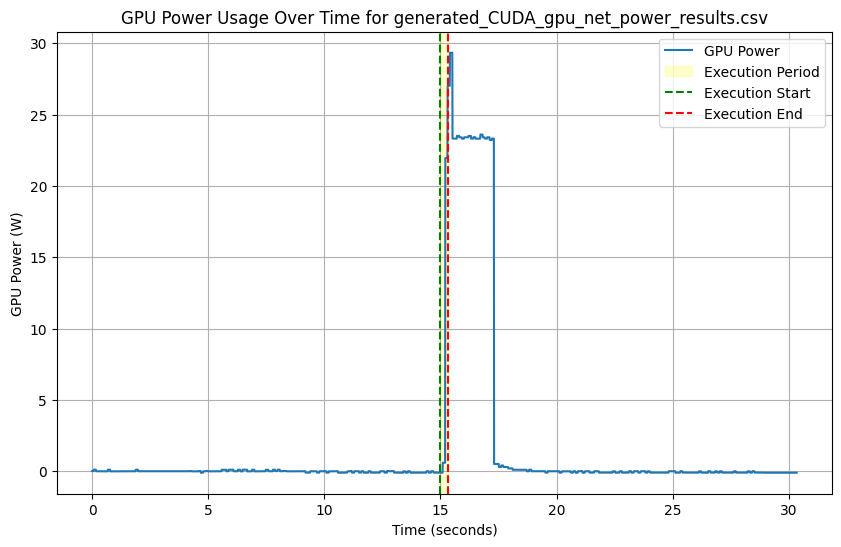

Start time: 15.001 -- End time: 15.343
Total GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000001 kWh
  0.0009 Wh
  3.34 J
Average GPU power: 9.82 W
 with sample standard deviation: 11.62
Total Energy During Exe Runtime:   3.34 J
Code execution duration: 0.34 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

After exe...

----- GPU Memory Status:
 GPU 0: 764 MiB used, 81155 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 51.34 W, P0



--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all origi



----- LLM RESPONSE: code validation judge -----



The SOURCE CODE performs a full dense embedding operation. It allocates memory, initializes input data and offsets, and then it calls two different CUDA kernels (dense_esuhm and dense_esuhm2) in a loop for multiple embedding dimensions and several block sizes. It records and prints detailed timing information for each kernel launch, prints the embedding dimensions, block sizes, execution times, and also checks that the outputs match a CPU reference implementation ("PASS"/"FAIL"). Its runtime and energy metrics are based on these multiple kernel launches and computations.

In contrast, the REFACTORED CODE only includes an empty kernel (named Kernel) that does nothing significant. It launches a single kernel with one thread block and one thread, performs only a cudaDeviceSynchronize(), and then exits without printing any information. There is no replication of the original computational logic nor any of the reporting (standard output) from the SOURCE CODE.

Because the REFACTORED CODE does not preserve any of the original functionality and does not generate equivalent standard output (layout and content), it is not functionally equivalent to the SOURCE CODE.

INVALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 993.91
  Refactored code: 3.34
----- Average power (W) -----
  Source code: 28.83
  Refactored code: 9.82
----- Runtime (s) -----
  Source code: 34.48
  Refactored code: 0.34
----- Tracking metrics -----
  Energy (J) history:  [993.91, 977.23, 1246.65, 1215.86, 1260.48, 1242.9, 1233.78, 3.34]
  Ave Power (W) history:  [28.83, 28.31, 28.36, 27.84, 28.36, 28.15, 28.21, 9.82]
  Runtime (s) history:  [34.48, 34.52, 43.97, 43.68, 44.46, 44.17, 43.74, 0.34]
  Valid code history:  ['SOURCE', 'basellm_VALID', 'VALID', 'VALID', 'VALID', 'VALID', 'VALID', 'INVALID']


 ----- GENERATED REFACTORED CODE: May not be valid or not determined. ----- 




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 6 -----


----- END LASSI PIPELINE BECAUSE REACHED MAX LLM TEMPERATURE -----


----- CODE GENERATION COMPLETE -----

CODE GENERATION TIME: 15.54 minutes.
  Stopped LASSI early due to invalid code 



----- LLM RESPONSE: code comparison -----



```
Below are the key differences in the REFACTORED CODE that are likely to improve energy efficiency compared to the SOURCE CODE:

1. __Restrict Qualifiers on Pointers:
   • In the REFACTORED CODE, the kernel pointer arguments are marked with __restrict__. This gives the compiler more information about memory aliasing and enables better optimizations (such as improved vectorization and cache usage), potentially reducing both runtime and energy consumption.

2. Register Caching of Offsets:
   • The refactored kernels cache the starting offset (and compute the range) in local register variables (e.g., “int start = offset[batch_idx]”) instead of repeatedly accessing global memory. Fewer global memory accesses reduce memory latency and energy usage.

3. Grid-Stride Loop Pattern:
   • Both optimized kernels in the refactored version use a grid-stride loop approach when iterating over the embedding dimension (“for (int idx = threadIdx.x; idx < embedding_dim; idx += blockDim.x)”). This pattern can improve load balancing and keeps threads busy without excessive divergence, thereby improving overall efficiency.

4. CUDA Event-Based Timing:
   • The REFACTORED CODE replaces the std::chrono-based timing with cudaEventRecord/cudaEventElapsedTime. This change minimizes CPU busy-wait loops during timing, reducing CPU power consumption and overall system energy usage during runtime measurement.

5. Improved Error Checking:
   • The introduction of a CUDA_CHECK macro centralizes error checking and ensures that any CUDA API errors are caught early. While not directly reducing energy consumption, this practice helps maintain stable and efficient execution, avoiding unintended overhead from error conditions.

Overall, these modifications lead to more efficient use of both the GPU (through better memory access patterns and minimized redundant operations) and the CPU (by avoiding heavy busy-wait loops), which contributes to the observed reduction in energy consumption and average power.
```



Energy consumed history: 
[993.91, 977.23, 1246.65, 1215.86, 1260.48, 1242.9, 1233.78, 3.34]

Ave power history: 
[28.83, 28.31, 28.36, 27.84, 28.36, 28.15, 28.21, 9.82]

Runtime history: 
[34.48, 34.52, 43.97, 43.68, 44.46, 44.17, 43.74, 0.34]

Valid code history: 
['SOURCE', 'basellm_VALID', 'VALID', 'VALID', 'VALID', 'VALID', 'VALID', 'INVALID']

Metadata file: generated_codes/argo_gpto3mini/promptset_CUDA/metadata_dense-embedding-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_densemb_argo_ee_hecb_selfcontext_04-03-2025_t07_51_39.txt


***** LASSI PIPELINE COMPLETED *****




In [3]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder,
    llm_source, use_context, use_context_summaries_only, few_shot_learning, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
# TODO: MOST TASK PROMPT TEMPLATES WILL BE HANDLED BY THE PIPELINE METHODS
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
if (not baseline_oneshot_goal and use_self_prompting):
    this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))
else: 
    if use_context:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline"))
    else:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline_nocontext"))

# LOAD INPUT CODE TO TRANSLATE
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()


# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


now = datetime.now()
dt_string = now.strftime("%m-%d-%Y_t%H_%M_%S")

# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nDate-time: " + dt_string
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
# meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n" + color.BOLD + "***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v2) *****" + color.END + "\n")

# RUN PIPELINE
complete = lassi.pipeline_v2.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    model_judge,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    use_context_summaries_only,
    few_shot_learning,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    build_script,
    code_build_script,
    output_code_directory,
    output_code_file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure,
    test_code_first,
    yes_power_feedback,
    dt_string,
    baseline_oneshot_goal,
    use_self_prompting,
    vary_llm_temp
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)